In [ ]:
!pip install pybaseball

Gathering player lookup table. This may take a moment.
No identically matched names found! Returning the 5 most similar names.
No identically matched names found! Returning the 5 most similar names.
No identically matched names found! Returning the 5 most similar names.
!! No exact match for William Hopkins. Closest:
name_first name_last  mlb_played_last
   william   kinsler           1893.0
   william     parks              NaN
   william     jones              NaN
   william  robinson           1892.0
   william      ross           1929.0
No identically matched names found! Returning the 5 most similar names.
Pulling hitter Liam Hicks...
Gathering Player Data
Pulling hitter Nick Fortes...
Gathering Player Data
Pulling hitter Jonathan Aranda...
Gathering Player Data
Pulling hitter Richie Palacios...
Gathering Player Data
Pulling hitter Ben Williamson...
Gathering Player Data
Pulling hitter Taylor Walls...
Gathering Player Data
Pulling hitter Jorge Mateo...
Gathering Player Data
Pullin

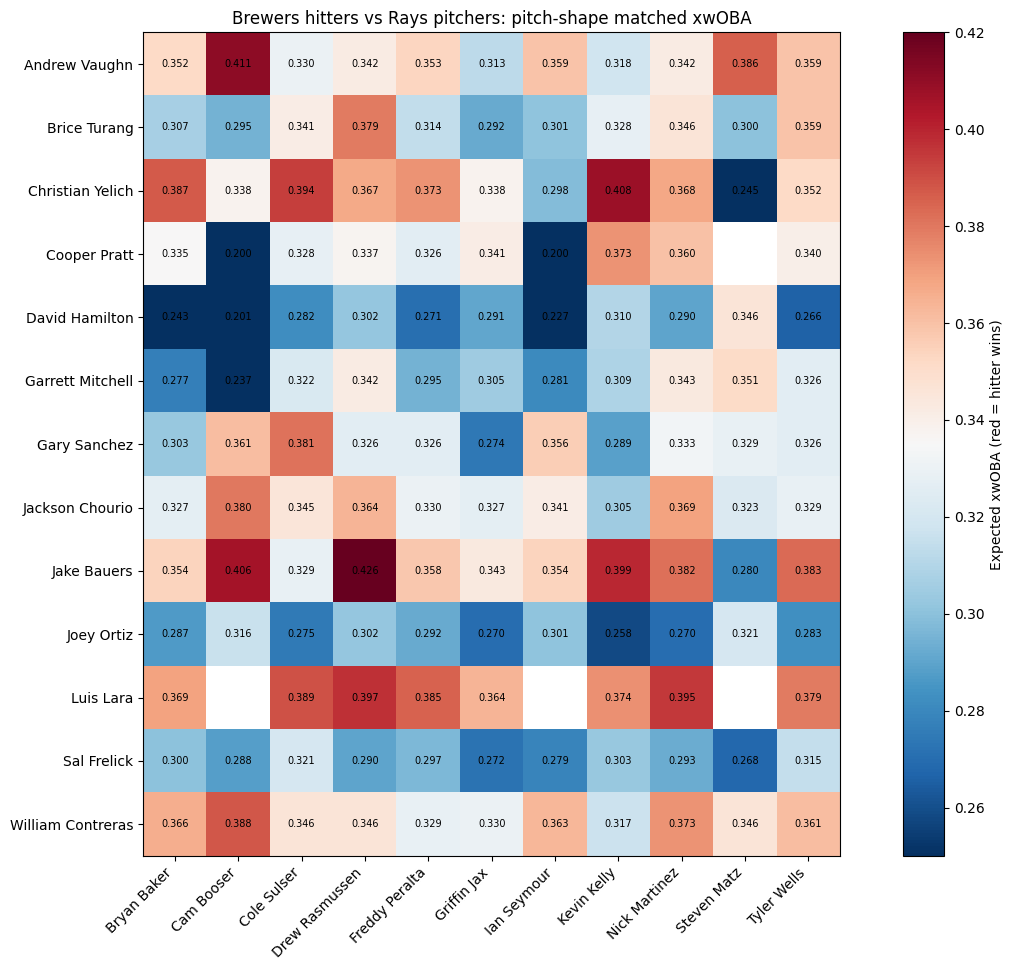

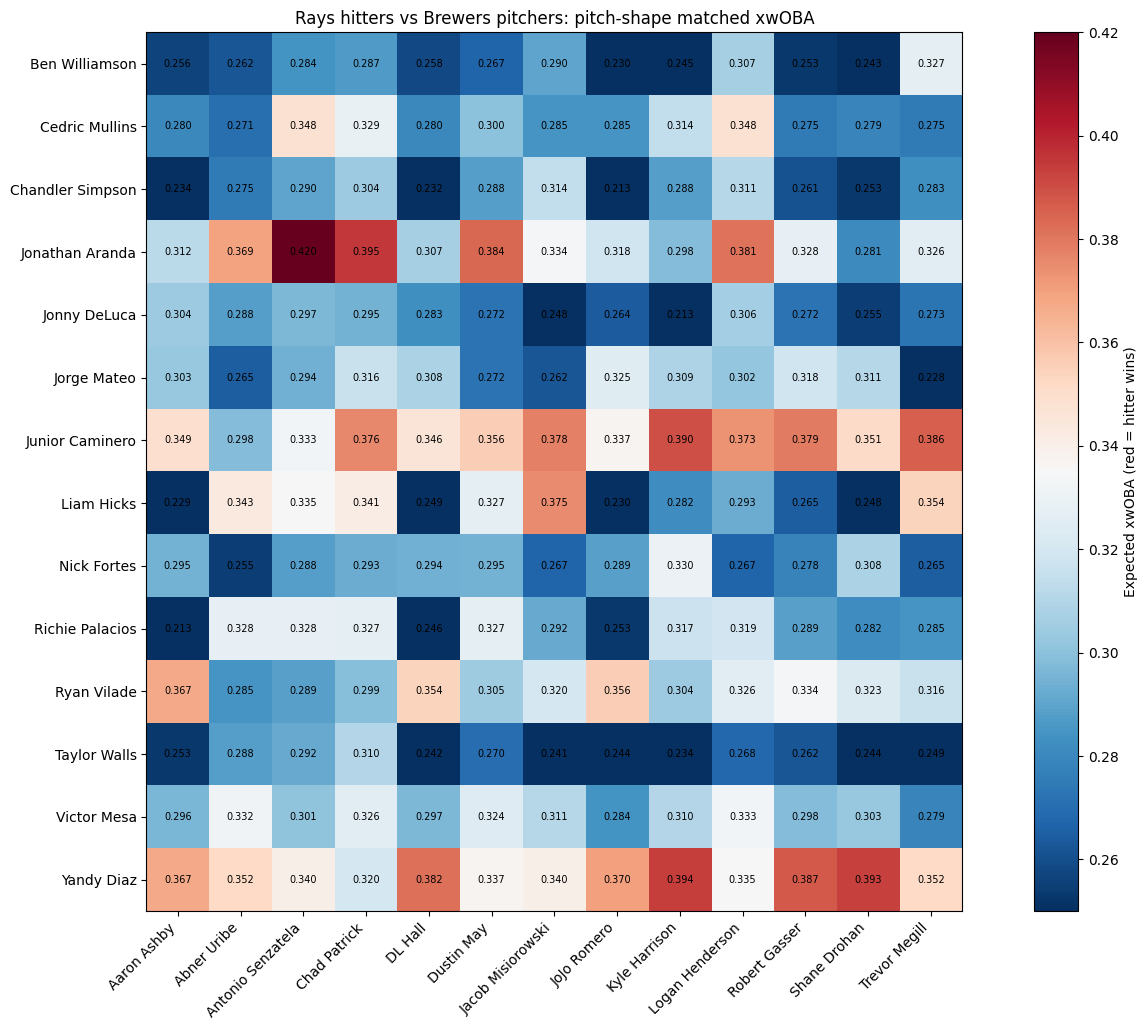

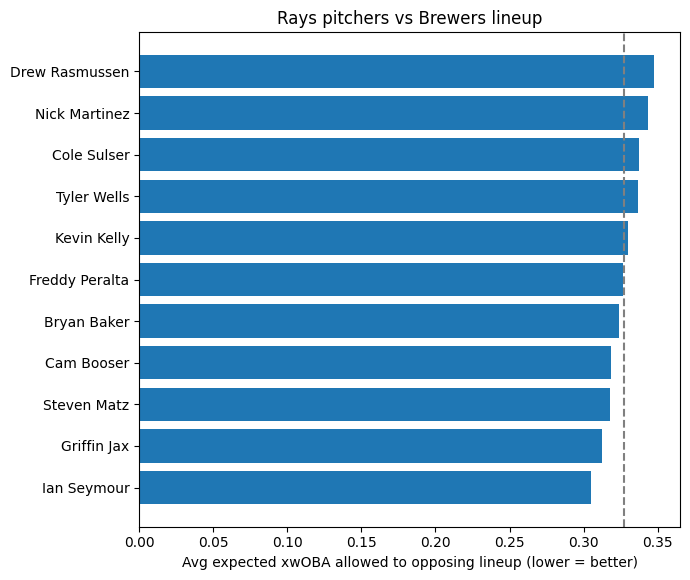

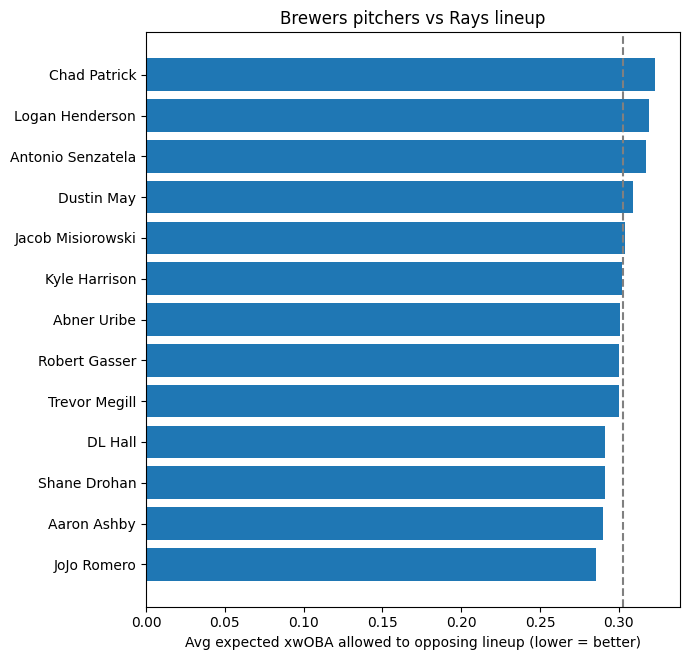


Rays pitchers vs Brewers lineup
           batter        pitcher  xwOBA_shrunk  xwOBA_raw  coverage
     Cooper Pratt    Ian Seymour         0.200      0.200     0.274
     Cooper Pratt     Cam Booser         0.200      0.200     0.440
   David Hamilton     Cam Booser         0.201      0.206     0.556
   David Hamilton    Ian Seymour         0.227      0.228     0.707
 Garrett Mitchell     Cam Booser         0.237      0.198     0.556
   David Hamilton    Bryan Baker         0.243      0.211     1.000
 Christian Yelich    Steven Matz         0.245      0.247     1.000
       Joey Ortiz    Kevin Kelly         0.258      0.251     0.999
   David Hamilton    Tyler Wells         0.266      0.252     1.000
      Sal Frelick    Steven Matz         0.268      0.252     0.584
       Joey Ortiz  Nick Martinez         0.270      0.270     0.999
       Joey Ortiz    Griffin Jax         0.270      0.275     1.001
   David Hamilton Freddy Peralta         0.271      0.263     1.000
      Sal Freli

In [ ]:
# World Series 2026 preview: pitch-shape matchup model (v3)
# Run in Google Colab. First cell:  !pip install pybaseball
#
# IDEA: for each pitcher and each of his pitch types, find the pitches a
# hitter has faced that look most like it (same pitch type, same throwing hand,
# closest velocity / spin rate / movement). Measure how the hitter did against
# those look-alikes, then shrink that toward his overall results vs that pitch
# type. Weight by the pitcher's pitch mix to get one expected xwOBA per matchup.

import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pybaseball import statcast_batter, statcast_pitcher, playerid_lookup, cache

cache.enable()

# ---- 1. Settings you can tweak ----
BAT_START = "2021-03-01"    # how far back to pull hitters (longer = slower)
PITCH_START = "2026-03-01"  # pitcher profile = this season's pitches
END = "2026-10-19"
FEATURES = ["release_speed", "release_spin_rate", "pfx_x", "pfx_z"]
K = 30           # how many look-alike pitches to use per hitter
MIN_POOL = 25    # skip if hitter has fewer PA vs that pitch type and hand
MIN_USAGE = 0.05 # ignore pitch types a pitcher throws under 5% of the time
SHRINK_PA = 30   # strength of shrinkage toward the hitter's overall result
# Sweepers and slurves are grouped with sliders and curves; the movement
# matching below still separates them by shape.
GROUP = {"ST": "SL", "SV": "SL", "KC": "CU"}

# ---- 2. Rosters ----
RAYS_BATTERS = [
    ("Liam", "Hicks"), ("Nick", "Fortes"), ("Jonathan", "Aranda"),
    ("Richie", "Palacios"), ("Ben", "Williamson"), ("Taylor", "Walls"),
    ("Jorge", "Mateo"), ("Junior", "Caminero"), ("Chandler", "Simpson"),
    ("Cedric", "Mullins"), ("Jonny", "DeLuca"), ("Victor", "Mesa"),
    ("Ryan", "Vilade"), ("Yandy", "Diaz"),
]
RAYS_PITCHERS = [
    ("Griffin", "Jax"), ("Nick", "Martinez"), ("Steven", "Matz"),
    ("Freddy", "Peralta"), ("Drew", "Rasmussen"), ("William", "Hopkins"),
    ("Bryan", "Baker"), ("Kevin", "Kelly"), ("Ian", "Seymour"),
    ("Cam", "Booser"), ("Tyler", "Wells"), ("Cole", "Sulser"),
]
BREWERS_BATTERS = [
    ("William", "Contreras"), ("Gary", "Sanchez"), ("Jake", "Bauers"),
    ("Andrew", "Vaughn"), ("Brice", "Turang"), ("Joey", "Ortiz"),
    ("Cooper", "Pratt"), ("David", "Hamilton"), ("Jackson", "Chourio"),
    ("Garrett", "Mitchell"), ("Sal", "Frelick"), ("Luis", "Lara"),
    ("Christian", "Yelich"),
]
BREWERS_PITCHERS = [
    ("Dustin", "May"), ("Jacob", "Misiorowski"), ("Logan", "Henderson"),
    ("Kyle", "Harrison"), ("Robert", "Gasser"), ("Aaron", "Ashby"),
    ("Trevor", "Megill"), ("JoJo", "Romero"), ("DL", "Hall"),
    ("Chad", "Patrick"), ("Abner", "Uribe"), ("Antonio", "Senzatela"),
    ("Shane", "Drohan"),
]


# ---- 3. Player ID lookup ----
def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFD", str(s))
                   if unicodedata.category(c) != "Mn").lower()


def get_id(first, last):
    res = playerid_lookup(last, first, fuzzy=True)
    if res.empty:
        print(f"!! Not found: {first} {last}")
        return None
    res = res.copy()
    res["mlb_played_last"] = pd.to_numeric(res["mlb_played_last"], errors="coerce")
    res = res[res["key_mlbam"].notna()]
    last_n = res["name_last"].map(strip_accents)
    first_n = res["name_first"].map(strip_accents)
    exact = res[(first_n == strip_accents(first)) & (last_n == strip_accents(last))]
    if exact.empty:
        recent = res[(last_n == strip_accents(last)) & (res["mlb_played_last"] >= 2024)]
        if len(recent) == 1:
            row = recent.iloc[0]
            print(f"~ Using {row['name_first']} {row['name_last']} for {first} {last}")
            return int(row["key_mlbam"])
        print(f"!! No exact match for {first} {last}. Closest:")
        print(res[["name_first", "name_last", "mlb_played_last"]].to_string(index=False))
        return None
    exact = exact.sort_values("mlb_played_last", ascending=False)
    return int(exact.iloc[0]["key_mlbam"])


def build_ids(players):
    out = {}
    for first, last in players:
        pid = get_id(first, last)
        if pid:
            out[pid] = f"{first} {last}"
    return out


rays_b = build_ids(RAYS_BATTERS)
rays_p = build_ids(RAYS_PITCHERS)
brew_b = build_ids(BREWERS_BATTERS)
brew_p = build_ids(BREWERS_PITCHERS)


# ---- 4. Hitters: pull career pitches, keep plate-appearance-ending pitches ----
def prep_pa(df):
    pa = df[df["events"].notna()].copy()
    pa = pa[pa["woba_denom"].fillna(0) == 1]  # drops bunts, IBB, etc.
    # xwOBA: Statcast estimate on balls in play, actual wOBA value on K/BB/HBP
    pa["xw"] = pa["estimated_woba_using_speedangle"].fillna(pa["woba_value"])
    pa["pt"] = pa["pitch_type"].replace(GROUP)
    return pa.dropna(subset=FEATURES + ["pt", "p_throws", "xw"])


bat_pa = {}
for pid, name in {**rays_b, **brew_b}.items():
    print(f"Pulling hitter {name}...")
    try:
        df = statcast_batter(BAT_START, END, pid)
    except Exception as e:
        print(f"!! Failed for {name}: {e}")
        continue
    if df is not None and not df.empty:
        bat_pa[name] = prep_pa(df)


# ---- 5. Pitchers: build this season's pitch-shape profile ----
def pitcher_profile(df):
    d = df.copy()
    d["pt"] = d["pitch_type"].replace(GROUP)
    d = d.dropna(subset=FEATURES + ["pt"])
    if d.empty:
        return None
    hand = d["p_throws"].mode()[0]
    prof = d.groupby("pt").agg(
        n=("pt", "size"),
        **{f: (f, "mean") for f in FEATURES},
    ).reset_index()
    prof["usage"] = prof["n"] / prof["n"].sum()
    prof = prof[prof["usage"] >= MIN_USAGE].copy()
    prof["usage"] = prof["usage"] / prof["usage"].sum()
    return hand, prof


profiles = {}
for pid, name in {**rays_p, **brew_p}.items():
    print(f"Pulling pitcher {name}...")
    try:
        df = statcast_pitcher(PITCH_START, END, pid)
    except Exception as e:
        print(f"!! Failed for {name}: {e}")
        continue
    if df is None or df.empty:
        print(f"!! No 2026 data for {name}")
        continue
    p = pitcher_profile(df)
    if p:
        profiles[name] = p


# ---- 6. The matchup model ----
def compute(batter_names, pitcher_names):
    rows = []
    for b in batter_names:
        pa = bat_pa.get(b)
        if pa is None or pa.empty:
            continue
        for p in pitcher_names:
            if p not in profiles:
                continue
            hand, prof = profiles[p]
            for _, r in prof.iterrows():
                pool = pa[(pa["pt"] == r["pt"]) & (pa["p_throws"] == hand)]
                if len(pool) < MIN_POOL:
                    continue
                X = pool[FEATURES].to_numpy(float)
                sd = X.std(axis=0)
                sd[sd == 0] = 1
                target = r[FEATURES].to_numpy(float)
                dist = np.sqrt((((X - target) / sd) ** 2).sum(axis=1))
                idx = np.argsort(dist)[:K]
                matched = pool["xw"].to_numpy()[idx].mean()
                prior = pool["xw"].mean()
                n = len(idx)
                shrunk = (n * matched + SHRINK_PA * prior) / (n + SHRINK_PA)
                rows.append(dict(batter=b, pitcher=p, pitch=r["pt"],
                                 usage=round(r["usage"], 3), n_matched=n,
                                 avg_dist=round(dist[idx].mean(), 2),
                                 raw=round(matched, 3), prior=round(prior, 3),
                                 shrunk=round(shrunk, 3)))
    return pd.DataFrame(rows)


def rollup(detail):
    d = detail.copy()
    d["wn"] = d["usage"] / d.groupby(["batter", "pitcher"])["usage"].transform("sum")
    d["s"] = d["wn"] * d["shrunk"]
    d["r"] = d["wn"] * d["raw"]
    out = d.groupby(["batter", "pitcher"]).agg(
        xwOBA_shrunk=("s", "sum"), xwOBA_raw=("r", "sum"),
        coverage=("usage", "sum")).reset_index()
    return out.round(3)


brew_detail = compute(brew_b.values(), rays_p.values())   # Brewers hitters vs Rays arms
rays_detail = compute(rays_b.values(), brew_p.values())   # Rays hitters vs Brewers arms
brew_roll = rollup(brew_detail) if not brew_detail.empty else pd.DataFrame()
rays_roll = rollup(rays_detail) if not rays_detail.empty else pd.DataFrame()


# ---- 7. Look at one matchup in detail, e.g. show(brew_detail, "Christian Yelich", "Steven Matz") ----
def show(detail, batter, pitcher):
    sub = detail[(detail["batter"] == batter) & (detail["pitcher"] == pitcher)]
    print(sub.drop(columns=["batter", "pitcher"]).to_string(index=False))


# ---- 8. Charts ----
def heatmap(roll, title):
    if roll.empty:
        print(f"No data for: {title}")
        return
    piv = roll.pivot(index="batter", columns="pitcher", values="xwOBA_shrunk")
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * piv.shape[1] + 3),
                                    max(4, 0.6 * piv.shape[0] + 2)))
    im = ax.imshow(piv.values.astype(float), cmap="RdBu_r", vmin=0.25, vmax=0.42)
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels(piv.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels(piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.iloc[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
    fig.colorbar(im, label="Expected xwOBA (red = hitter wins)")
    plt.tight_layout()
    plt.show()


def pitcher_bars(roll, title):
    if roll.empty:
        return
    s = roll.groupby("pitcher")["xwOBA_shrunk"].mean().sort_values()
    fig, ax = plt.subplots(figsize=(7, max(3, 0.4 * len(s) + 1.5)))
    ax.barh(s.index, s.values)
    ax.axvline(s.mean(), linestyle="--", color="gray")
    ax.set_xlabel("Avg expected xwOBA allowed to opposing lineup (lower = better)")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


heatmap(brew_roll, "Brewers hitters vs Rays pitchers: pitch-shape matched xwOBA")
heatmap(rays_roll, "Rays hitters vs Brewers pitchers: pitch-shape matched xwOBA")
pitcher_bars(brew_roll, "Rays pitchers vs Brewers lineup")
pitcher_bars(rays_roll, "Brewers pitchers vs Rays lineup")

print("\nRays pitchers vs Brewers lineup")
print(brew_roll.sort_values("xwOBA_shrunk").to_string(index=False))
print("\nBrewers pitchers vs Rays lineup")
print(rays_roll.sort_values("xwOBA_shrunk").to_string(index=False))


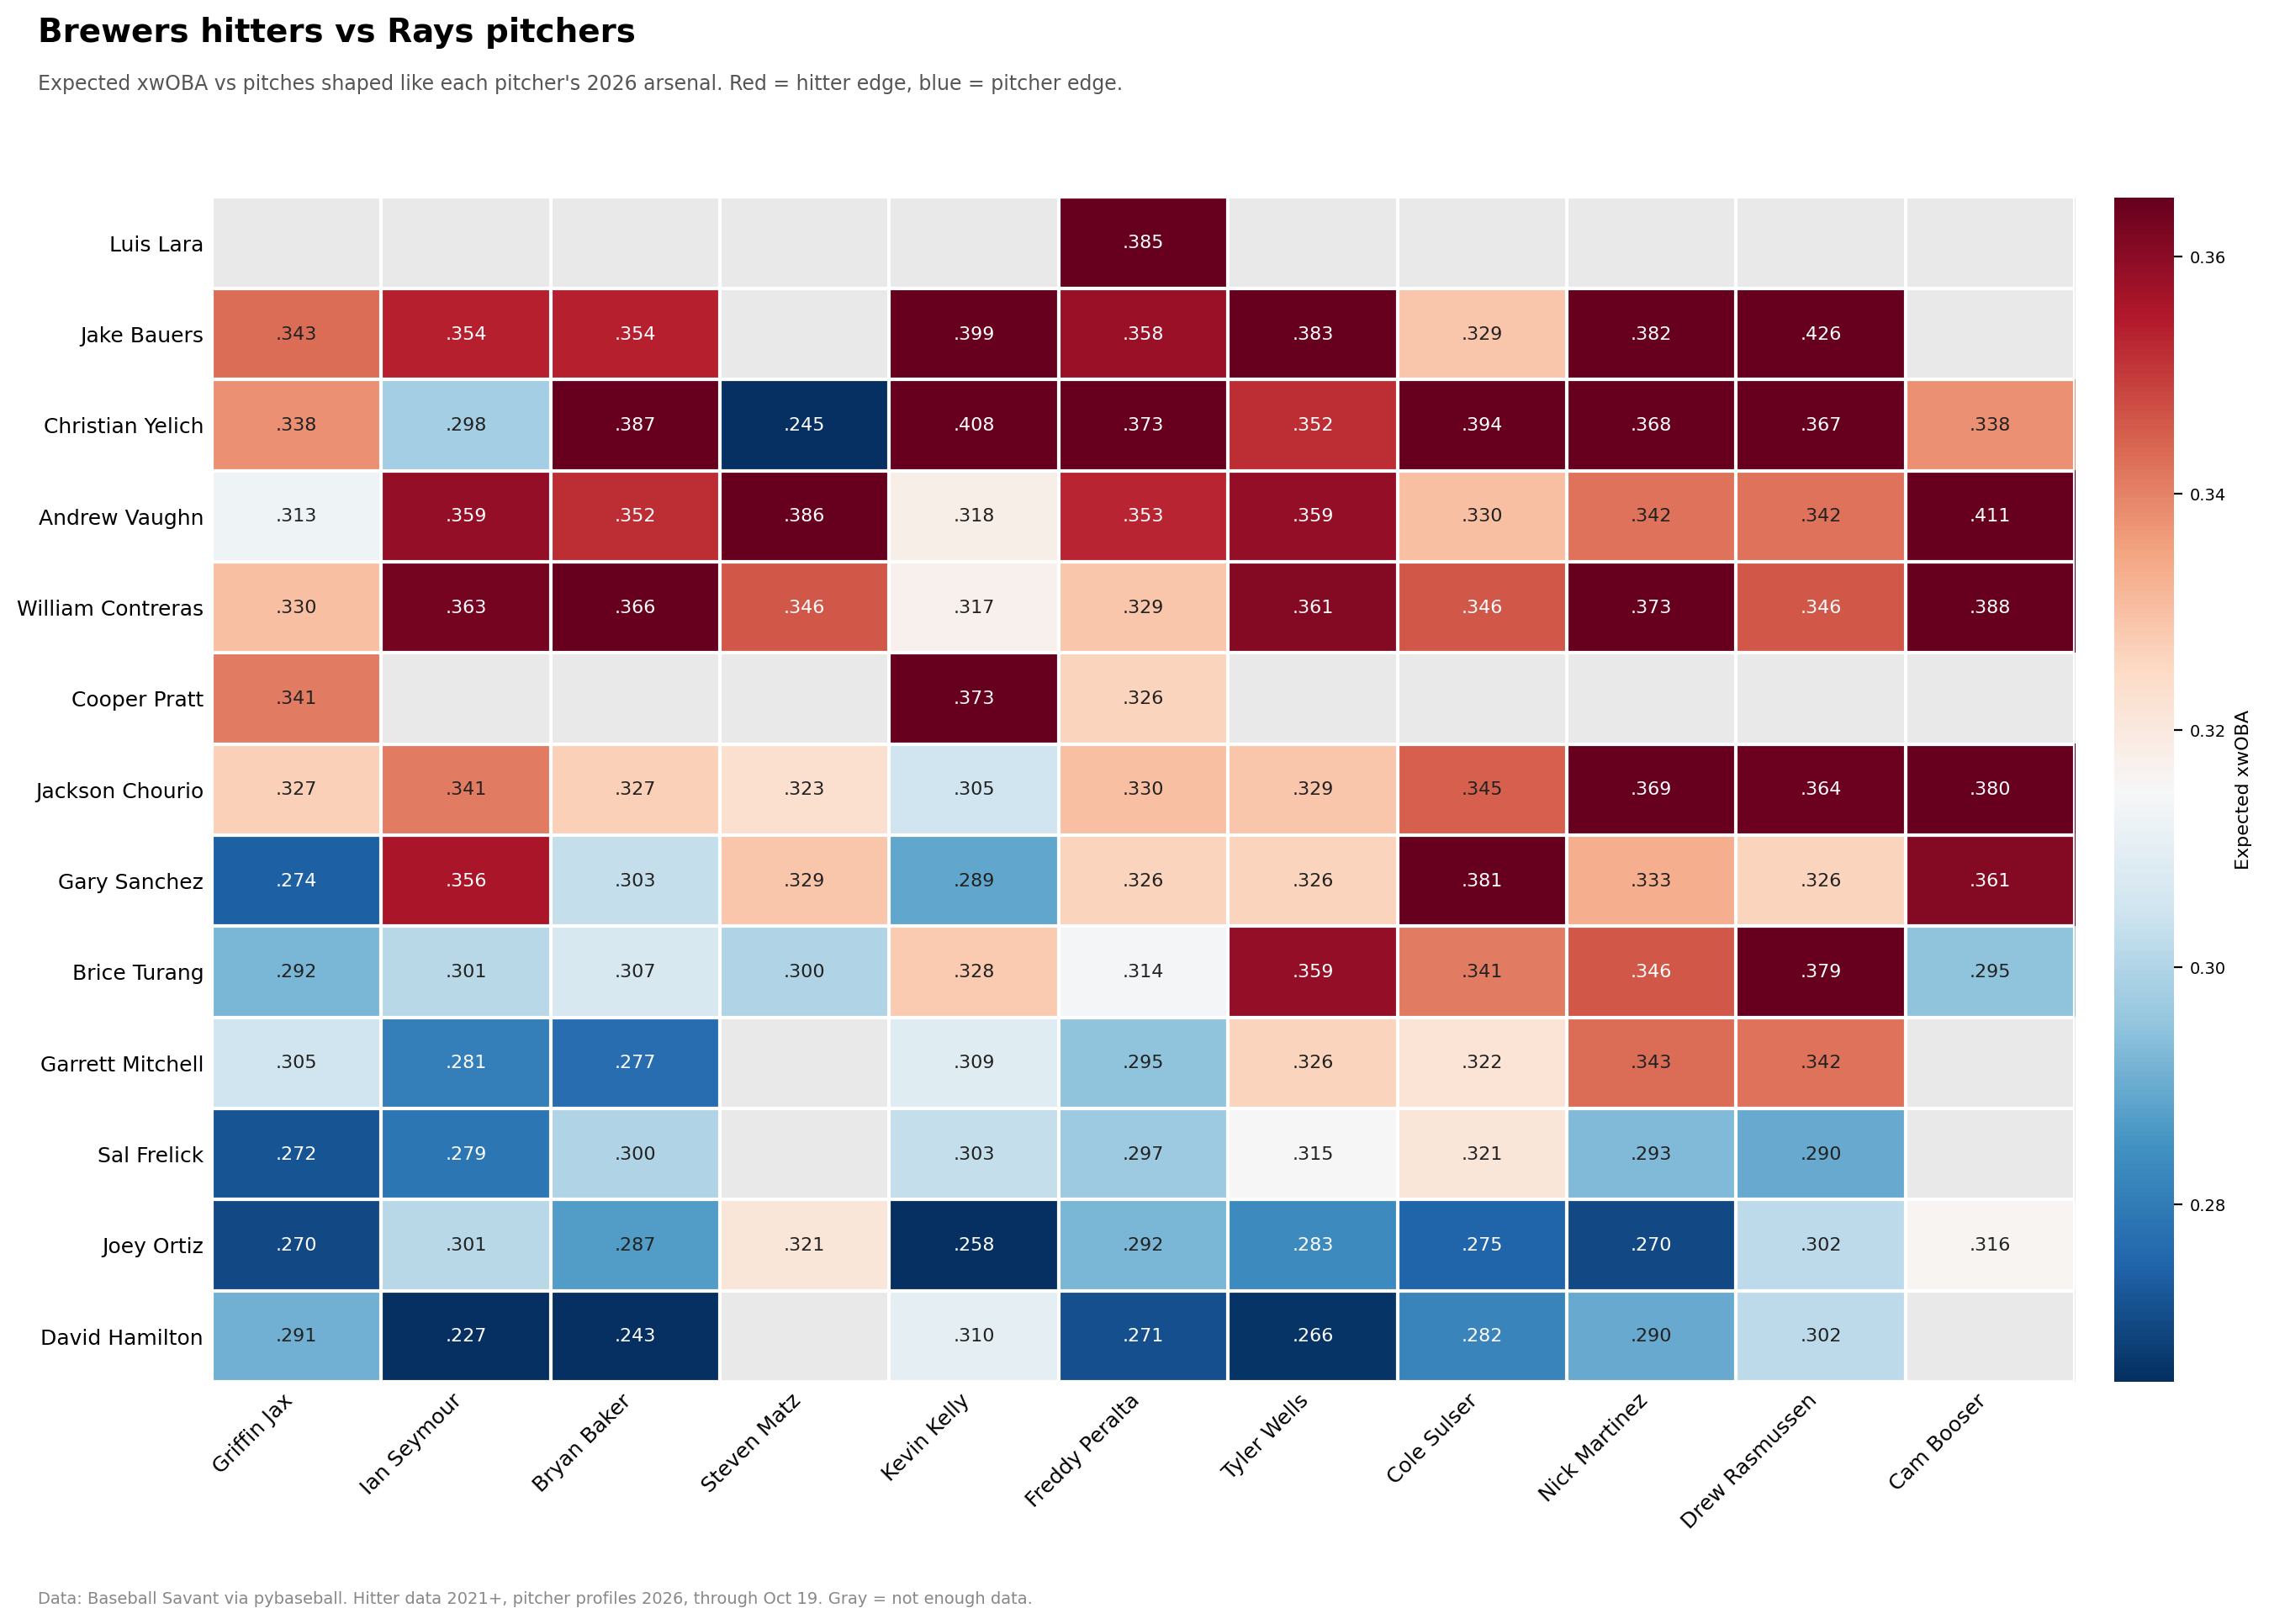

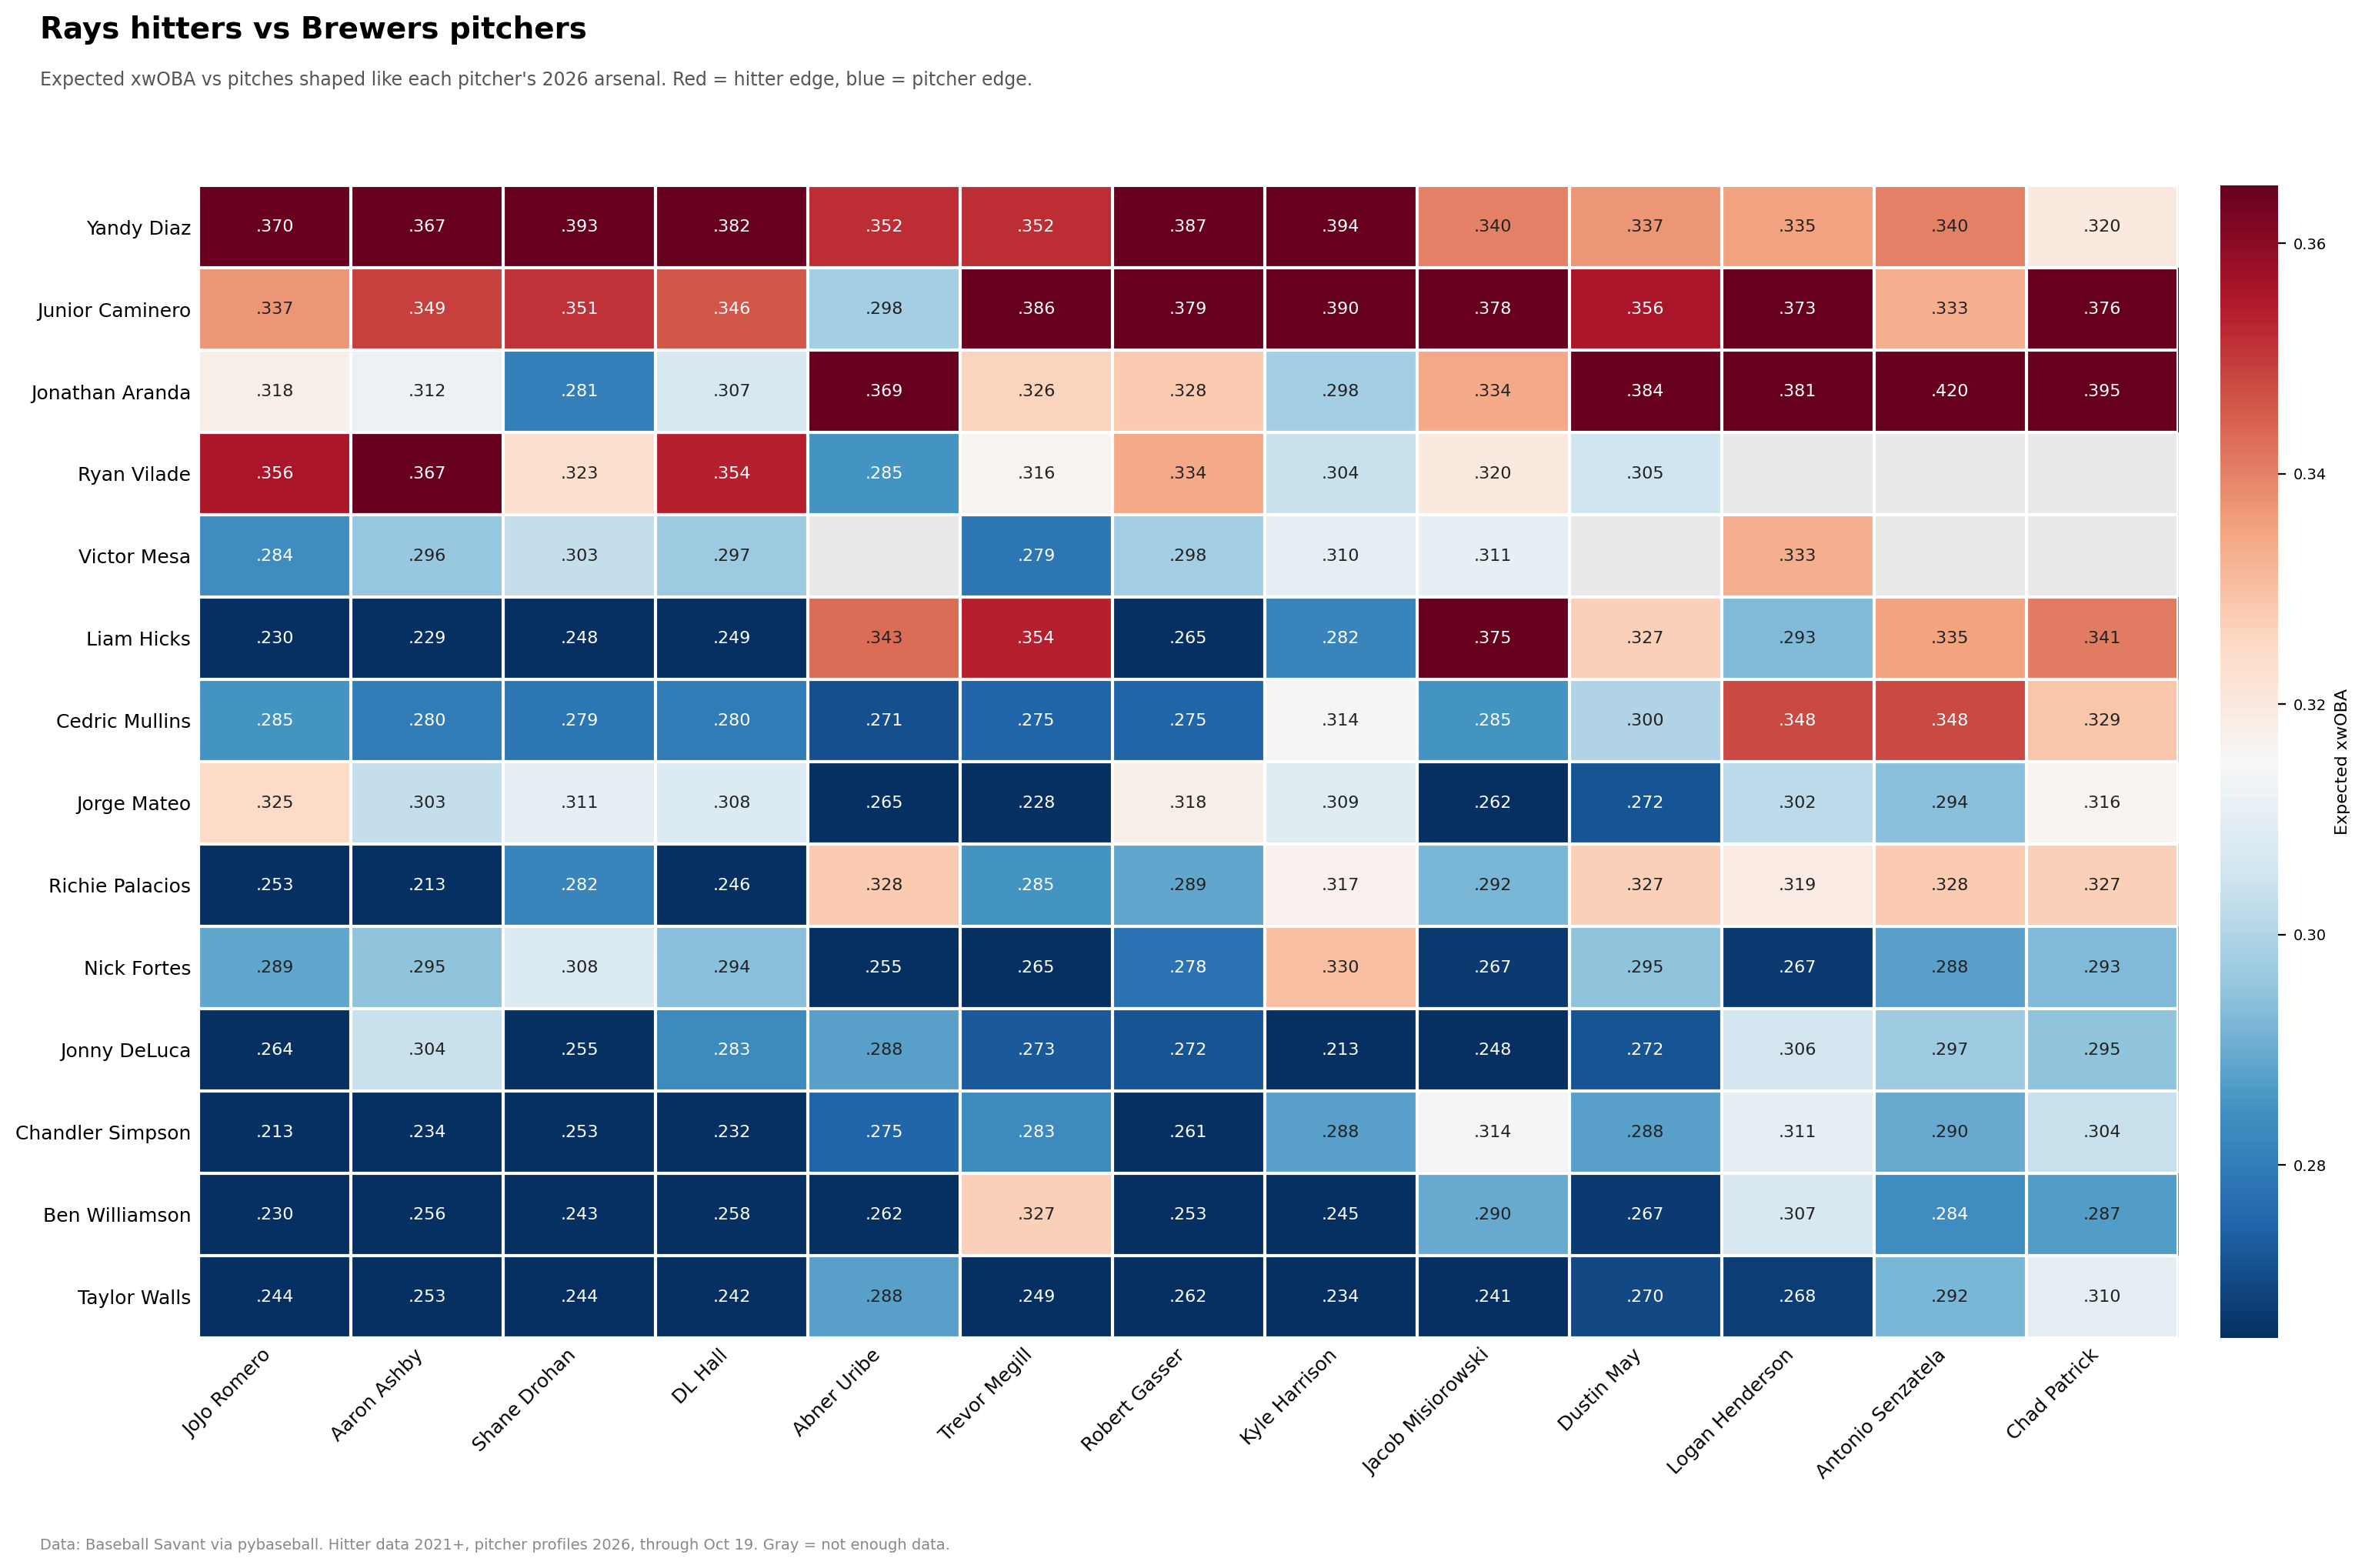

In [ ]:
# ---- Tweet-ready heatmaps ----
# Paste this into a NEW cell below your model code and run it after the
# model cells finish. It uses brew_roll and rays_roll from the model.
# To save a chart on your phone, long-press the image and tap Save.

import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

LEAGUE_XWOBA = 0.315   # white = about league average
SPREAD = 0.05          # colors max out at average +/- this much
MIN_COVERAGE = 0.6     # gray out cells where the model covered <60% of the pitcher's mix

SUBTITLE = ("Expected xwOBA vs pitches shaped like each pitcher's 2026 arsenal. "
            "Red = hitter edge, blue = pitcher edge.")
FOOTER = ("Data: Baseball Savant via pybaseball. Hitter data 2021+, pitcher profiles 2026, "
          "through Oct 19. Gray = not enough data.")


def tweet_heatmap(roll, title, filename):
    if roll is None or roll.empty:
        print(f"No data for {title}")
        return
    d = roll.copy()
    d.loc[d["coverage"] < MIN_COVERAGE, "xwOBA_shrunk"] = np.nan
    piv = d.pivot(index="batter", columns="pitcher", values="xwOBA_shrunk")
    piv = piv.dropna(how="all").dropna(axis=1, how="all")

    # Best hitters on top, toughest pitchers on the left
    piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index,
                  piv.mean(axis=0).sort_values().index]
    vals = piv.to_numpy(float)
    n_rows, n_cols = vals.shape

    norm = TwoSlopeNorm(vcenter=LEAGUE_XWOBA,
                        vmin=LEAGUE_XWOBA - SPREAD, vmax=LEAGUE_XWOBA + SPREAD)
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("#e9e9e9")

    fig, ax = plt.subplots(figsize=(0.95 * n_cols + 3.2, 0.55 * n_rows + 2.6), dpi=200)
    im = ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, norm=norm, aspect="auto")

    # Cell labels: .342 style, white text on the dark cells so it stays readable
    for i in range(n_rows):
        for j in range(n_cols):
            v = vals[i, j]
            if np.isnan(v):
                continue
            dark = abs(v - LEAGUE_XWOBA) > SPREAD * 0.6
            ax.text(j, i, f"{v:.3f}".lstrip("0"), ha="center", va="center",
                    fontsize=8, color="white" if dark else "#222")

    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(piv.columns, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(piv.index, fontsize=9)
    ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cb.set_label("Expected xwOBA", fontsize=8)
    cb.ax.tick_params(labelsize=7)
    cb.outline.set_visible(False)

    width_chars = int(fig.get_figwidth() * 13)
    fig.suptitle(title, x=0.02, ha="left", fontsize=14, fontweight="bold")
    fig.text(0.02, 0.945, textwrap.fill(SUBTITLE, width_chars), ha="left", va="top",
             fontsize=8.5, color="#555")
    fig.text(0.02, 0.01, textwrap.fill(FOOTER, width_chars + 10), ha="left", va="bottom",
             fontsize=7, color="#888")
    fig.tight_layout(rect=(0, 0.04, 1, 0.92))
    fig.savefig(filename, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


tweet_heatmap(brew_roll, "Brewers hitters vs Rays pitchers", "brewers_vs_rays.png")
tweet_heatmap(rays_roll, "Rays hitters vs Brewers pitchers", "rays_vs_brewers.png")
